# A* pour plusieurs robot (sans tâche)

On utilise les classes existantes pour généraliser à un ensemble de robot qu'on affecte à une pièce.

In [1]:
# import de module

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pandas as pd
import networkx as nx
import tkinter as tk
import random
import math


### Classe Mur

In [27]:
class Mur:
    """ 
    Classe pour les murs de la pièce    
    """

    def __init__(self, position):
        """ 
        Paramètre:
        ----------
        position : liste de deux listes
            position des deux extrémités du mur
        """
        self.position = position
        self.longueur = np.sqrt(
            (position[1][0] - position[0][0])**2 + (position[1][1] - position[0][1])**2)
        self.type = "mur"

    def __repr__(self):
        return f"Mur de longueur {self.longueur} et de position {self.position}"

    def __str__(self):
        return f"{self.type} de longueur {self.longueur} et de position {self.position}"


print("Test de la classe Mur")
mur1 = Mur([[0, 0], [0, 1]])
print(mur1)

Test de la classe Mur
mur de longueur 1.0 et de position [[0, 0], [0, 1]]


### Classe Porte

In [28]:
# On créé une classe pour les portes de la pièce

class Porte:
    """
    Classe pour les portes de la pièce
    """

    def __init__(self, position, statut):
        """
        Constructeur de la classe
        Paramètres:
        -----------
        positon: position de la porte définis comme une liste des coordonnées de début et de fin (cf. murs)
        exemple : position = [[0,0], [0,1]]
        statut: ouvert ou fermé
        """

        self.position = position
        self.statut = statut
        self.largeur = np.sqrt(
            (position[1][0] - position[0][0])**2 + (position[1][1] - position[0][1])**2)
        self.type = "porte"

    def __str__(self):
        """
        Méthode pour afficher les informations de la porte
        :return: les informations de la porte
        """
        return f"Porte à la position {self.position} de largeur {self.largeur} et de statut {self.statut}"

    def __repr__(self):
        """
        Méthode pour afficher les informations de la porte
        :return: les informations de la porte
        """
        return f"Porte à la position {self.position} de largeur {self.largeur} et de statut {self.statut}"

    def ouvrir(self):
        """
        Méthode pour ouvrir la porte
        Ne retourne rien
        """
        self.statut = "ouverte"

    def fermer(self):
        """ 
        Méthode pour fermer la porte
        Ne retourne rien
        """
        self.statut = "fermee"


print("Test de la classe Porte")
porte1 = Porte([[0, 0], [0, 1]], "fermee")
print(porte1)

Test de la classe Porte
Porte à la position [[0, 0], [0, 1]] de largeur 1.0 et de statut fermee


### Classe Pièce

In [29]:
# On créer une pièce pour que le robot cicule dedans

class Piece:
    """
    Une pièce est définie par sa longueur, sa largeur et la liste des murs interne qui la compose.
    C'est par defaut un rectangle de longueur et largeur donnée.
    Les murs sont des segments de droite, définis par deux points en coordonnées cartésiennes
    """

    def __init__(self, longueur, largeur, liste_murs, liste_portes):
        '''
        Parameters :
        longueur : longueur de la pièce
        largeur : largeur de la pièce
        liste_murs : liste des murs de la pièce, sous la forme d'une liste de classe mur
        listes_portes : liste de portes de la pièce, sous la forme d'une liste de classe porte
        depart : coordonnées du point de départ du robot    
        arrivee : coordonnées du point d'arrivée du robot
        '''

        self.longueur = longueur
        self.largeur = largeur

        self.liste_murs = liste_murs  # sans les murs extérieurs, ni les portes fermées
        liste_position = [[[0, 0], [0, largeur]], [[0, largeur], [longueur, largeur]], [
            [longueur, largeur], [longueur, 0]], [[longueur, 0], [0, 0]]]
        self.murs_exterieurs = [Mur(position) for position in liste_position]

        self.liste_portes = liste_portes
        self.portes_ouvertes = [
            portes for portes in liste_portes if portes.statut == "ouverte"]
        self.portes_fermees = [
            portes for portes in liste_portes if portes.statut == "fermee"]

        # A modifier en introduisant une classe robot
        self.liste_robot = []
        self.robot_size = {}
        self.depart = []
        self.arrivee = []
        self.robot_associe = False

    def __repr__(self):
        if self.robot_associe:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, contenant le robot {self.robot.nom} "
        else:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, sans robot associé"

    def __str__(self):
        if self.robot_associe:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, contenant le robot {self.robot.nom} "
        else:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, sans robot associé"

    def associer_robot(self, robot):
        """
        Associe des robot à la pièce
        Paramètres:
        robot: robot à associer
        """
        self.liste_robot.append(robot)
        self.robot_associe = True

        # on dimentionne le parcours pour le plus gros robot. Là où il passe, tous les autres passent
        self.robot_size[robot] = robot.taille

        self.depart.append(robot.position)

    def afficher(self, plot_grille=True, grid_size=2, plot_accessible=False, plot_path=True):
        """
        Affiche la pièce
        """

        # On plot les mur et les portes fermées
        list_plot = [self.murs_exterieurs, self.liste_murs, self.portes_fermees]
        liste_couleur = ['black', 'black', 'red']
        liste_largeur = [3, 2, 2]

        plt.figure(figsize=(10, 10))
        for i in range(len(list_plot)):
            for mur in list_plot[i]:
                position = mur.position
                plt.plot(
                    [position[0][0], position[1][0]],
                    [position[0][1], position[1][1]],
                    color=liste_couleur[i],
                    linewidth=liste_largeur[i]
                )

        # On plot la grille
        if plot_grille:
            x_grille, y_grille = self.grille(grid_size)
            for x in x_grille:
                for y in y_grille:
                    plt.scatter(x, y, color='blue', marker='+', s=50, linewidth=1)

        # On plot le chemin trouvé
        demarage = self.depart

        if plot_path:
            colors = ['green', 'blue', 'red']

            for i in range(len(self.liste_robot)):
                # on trace le chemin pour chacun des robots
                robot = self.liste_robot[i]
                depart = demarage[i]
                pathes = self.plus_court_chemin_tsp(depart, grid_size, robot)

                couleur = colors[i]

                # Garantir que pathes seja uma lista de listas
                if isinstance(pathes[0], tuple):  
                    pathes = [pathes]  # Encapsular em uma lista

                # Desenhar o caminho inteiro
                for chemin in pathes:
                    plt.plot([p[0] for p in chemin], [p[1] for p in chemin], color=couleur, linewidth=4)

                # Marcar os pontos de início dos robôs
                plt.scatter(demarage[i][0], demarage[i][1], color='black',
                            marker='^', s=70, linewidth=4, label=f"Départ {robot.nom}")

        plt.title("TECHLAB")
        plt.legend()
        plt.axis('equal')
        plt.show()



    def grille(self, grid_size):
        """
        Renvoie la grille de la pièce
        Paramètres:
        grid_size: ecart entre deux points de la grille

        :return: x_grille, y_grille: coordonnées des points de la grille (listes de même taille)
        """

        # on crée une liste de points espacés de grid_size
        x_grille = np.arange(0, self.longueur + 1, grid_size)
        y_grille = np.arange(0, self.largeur + 1, grid_size)

        return x_grille, y_grille

    def coord_mur(self):
        """
        Renvoie les coordonnées des murs de la pièce sous la forme de deux listes
        """
        x_wall = []
        y_wall = []
        liste_murs = self.murs_exterieurs + self.liste_murs + self.portes_fermees
        for mur in liste_murs:
            x_wall.append([mur.position[0][0], mur.position[1][0]])
            y_wall.append([mur.position[0][1], mur.position[1][1]])

        return x_wall, y_wall

    def is_in_wall(self, x_test, y_test, robot_size, do_plot=True):
        """
        Renvoie True si le point (x_test, y_test) est à une distance inférieure à une marge (eg. robot_size) d'un mur, le robot est un cercle de rayon robot_size
        Paramètres:
        x_test, y: coordonnées du point à tester
        robot_size: rayon du robot

        """
        x_wall, y_wall = self.coord_mur()
        nb_murs = len(x_wall)

        for i in range(0, nb_murs):
            # On ne connait pas le mur de facon continue, on le connait par ses points extrêmes
            # on calcule le projeté orthogonal du point sur le mur
            wall = [[x_wall[i][0], y_wall[i][0]], [x_wall[i][1], y_wall[i][1]]]

            vecteur_mur = [wall[1][0]-wall[0][0], wall[1][1]-wall[0][1]]

            vecteur_point_robot = [x_test - wall[0][0], y_test - wall[0][1]]

            projete = np.dot(vecteur_point_robot, vecteur_mur) / \
                np.dot(vecteur_mur, vecteur_mur)
            point_projete = [wall[0][0]+projete*vecteur_mur[0],
                             wall[0][1] + projete*vecteur_mur[1]]

            # on verifie que le point projeté est bien sur le segment
            if point_projete[0] < min(wall[0][0], wall[1][0]) or point_projete[0] > max(wall[0][0], wall[1][0]):
                continue
            if point_projete[1] < min(wall[0][1], wall[1][1]) or point_projete[1] > max(wall[0][1], wall[1][1]):
                continue

            # sur le mur, forme avec le centre du robot un vecteur normal au mur
            dist_projete = np.sqrt(
                (x_test-point_projete[0])**2 + (y_test-point_projete[1])**2)
            if do_plot:
                # on veut que le robot soit à l'echelle sur le plot
                # cf. https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.scatter.html
                s = 172*robot_size
                plt.scatter(x_test, y_test, color='green',
                            marker='o', s=s, linewidth=4)
                plt.scatter(point_projete[0], point_projete[1],
                            color='red', marker='o', s=50, linewidth=2)
                plt.plot([wall[0][0], wall[1][0]], [wall[0][1],
                         wall[1][1]], color='black', linewidth=2)
            
            if dist_projete < robot_size:
                return True

        return False
    
    def bresenham_line(self, p1, p2):
        """
        Implémente l'algorithme de Bresenham pour tracer une ligne entre p1 et p2.
        Retourne une liste de points (x, y) représentant la ligne.

        p1, p2 : tuples (x, y) représentant les coordonnées des points de début et de fin.
        """
        x1, y1 = p1
        x2, y2 = p2
        points = []

        dx = abs(x2 - x1)
        dy = abs(y2 - y1)
        sx = 1 if x1 < x2 else -1
        sy = 1 if y1 < y2 else -1
        err = dx - dy

        while True:
            points.append((x1, y1))
            if x1 == x2 and y1 == y2:
                break
            e2 = 2 * err
            if e2 > -dy:
                err -= dy
                x1 += sx
            if e2 < dx:
                err += dx
                y1 += sy

        return points

    def seg_coupe_obstacle(self, p1, p2):
        """
        Vérifie si le segment [p1, p2] traverse un mur ou une porte fermée.
        Retourne True si le segment coupe un obstacle, sinon False.
        
        p1, p2 : points définissant le segment (tuples (x, y))
        """
        # Utiliser murs_exterieurs, liste_murs et portes_fermees comme obstacles
        obstacles = self.murs_exterieurs + self.liste_murs + self.portes_fermees
        
        for obs in range(len(obstacles)):
            # Coordonnées du segment obstacle
            (x1, y1), (x2, y2) = obstacles[obs].position
            mur_points = self.bresenham_line((x1, y1), (x2, y2))
                    
            # Vérifier si la ligne entre p1 et p2 passe par un point du mur
            for point in self.bresenham_line(p1, p2):
                if point in mur_points:
                    
                    return True  # Il y a une collision

        return False  # Aucun obstacle traversé
    

    def accessible(self, grid_size, robot):
        """
        Renvoie True si le point (x_test, y_test) est accessible, c'est à dire si il n'est pas trop proche un mur,
        ou dans une porte fermée
        Paramètres:
        x_test, y: coordonnées du point à tester
        robot_size: rayon du robot
        doplot: si True, affiche les point accessibles en orange
        """
        robot_size = self.robot_size[robot]
        x_grid, y_grid = self.grille(grid_size)

        accessible = []

        for i in range(len(x_grid)):
            for j in range(len(y_grid)):
                if not self.is_in_wall(x_grid[i], y_grid[j], robot_size, do_plot=False):
                    accessible.append((x_grid[i], y_grid[j]))

        return accessible

    def get_graphe(self, grid_size, robot):
        """
        Renvoie le graphe (liste d'ajacence) de la pièce, c'est à dire la grille de la pièce moins les points non accessibles
        Paramètres:
        grid_size: ecart entre deux points de la grille
        robot_size: rayon du robot
        doplot: si True, affiche le graphe

        """

        # on initialise le graphe comme un dictionnaire
        accessible = self.accessible(grid_size, robot)
        graphe = {}
        max_distance = grid_size * 3

        for i in range(len(accessible)):
            # pour tout sommet accessible, on cherche les plus proche voisins
            graphe[accessible[i]] = []
            for j in range(len(accessible)):
                if i == j:
                    continue
                dist = np.sqrt(
                    (accessible[i][0]-accessible[j][0])**2 + (accessible[i][1]-accessible[j][1])**2)
                # on ne relie que les points proches (diagonalement aussi)
                if dist <= max_distance and not self.seg_coupe_obstacle(accessible[i], accessible[j]):
                    # on verifie que le segment ne passe pas par un mur / une porte fermée

                    graphe[accessible[i]].append(accessible[j])

        return graphe

    def plus_court_chemin_tsp(self, depart, grid_size, robot, k=1):
        ''' 
        Fonction qui utilise uniquement le TSP pour trouver le chemin optimal entre toutes les tâches.
        Paramètres:
        - depart: coordonnées du point de départ (sous la forme d'une liste)
        - grid_size: écart entre deux points de la grille
        - robot: objet représentant le robot
        - k: facteur d'échelle

        Retourne:
        - Un chemin ordonné de points visités par le robot
        '''
        
        # Obtenir le graphe du robot
        graphe = nx.Graph(self.get_graphe(grid_size, robot))

        # Étape 1 : Construire la liste des lieux (tâches) à visiter
        liste_lieux = [(depart[0] * k, depart[1] * k)]  # Inclut le point de départ
        for tache in robot.taches:
            lieux = [[l[0] * k, l[1] * k] for l in tache.liste_lieux]
            liste_lieux += lieux

        # Étape 2 : Créer un graphe complet pour le TSP
        tsp_graph = nx.complete_graph(len(liste_lieux))
        positions = {i: tuple(liste_lieux[i]) for i in range(len(liste_lieux))}

        # Calculer les poids des arêtes (distances euclidiennes sur le graphe)
        for i in tsp_graph.nodes():
            for j in tsp_graph.nodes():
                if i != j:
                    try:
                        tsp_graph.edges[i, j]['weight'] = nx.shortest_path_length(
                            graphe, positions[i], positions[j], weight="weight"
                        )
                    except nx.NetworkXNoPath:
                        tsp_graph.edges[i, j]['weight'] = float('inf')  # Pénaliser chemins impossibles

        # Étape 3 : Trouver le chemin optimal avec le TSP
        tsp_cycle = nx.approximation.traveling_salesman_problem(
            tsp_graph, weight="weight", cycle=True
        )

        # Convertir la solution TSP en une liste de coordonnées réelles
        chemin_final = [positions[i] for i in tsp_cycle]

        return chemin_final

    
    def plus_court_chemin_tsp_otimise(self, depart, graphe, grid_size, robot, k=1):
        ''' 
        Fonction qui utilise le TSP pour trouver le chemin optimal entre toutes les tâches.
        Cette function est utilisé pour trouver le meiller point de depart
        Paramètres :
        - depart : coordonnées du point de départ.
        - graphe : graphe déjà construit pour éviter de le recalculer.
        - grid_size : écart entre deux points de la grille.
        - robot : objet représentant le robot.
        - k : facteur d'échelle.

        Retourne :
        - pathes : Liste des chemins optimaux.
        - etapes : Liste des étapes du chemin.
        - distance_totale : Somme des longueurs des chemins.
        '''

        # Étape 1 : Construire la liste des lieux (tâches) à visiter
        liste_lieux = [(depart[0] * k, depart[1] * k)]  # Inclut le point de départ
        for tache in robot.taches:
            lieux = [[l[0] * k, l[1] * k] for l in tache.liste_lieux]
            liste_lieux += lieux

        # Étape 2 : Créer un graphe complet pour le TSP
        tsp_graph = nx.complete_graph(len(liste_lieux))
        positions = {i: tuple(liste_lieux[i]) for i in range(len(liste_lieux))}

        # Calculer les poids des arêtes (distances euclidiennes)
        for i in tsp_graph.nodes():
            for j in tsp_graph.nodes():
                if i != j:
                    try:
                        tsp_graph.edges[i, j]['weight'] = nx.shortest_path_length(graphe, positions[i], positions[j], weight="weight")
                    except nx.NetworkXNoPath:
                        tsp_graph.edges[i, j]['weight'] = float('inf')  # Penaliza caminhos impossíveis

        # Étape 3 : Trouver le chemin optimal avec le TSP
        tsp_cycle = nx.approximation.traveling_salesman_problem(
            tsp_graph, weight="weight", cycle=True
        )

        # Étape 4 : Convertir les indices du TSP en coordonnées réelles
        pathes = []
        etapes = []
        distance_totale = 0

        for i in range(len(tsp_cycle) - 1):
            start_idx = tsp_cycle[i]
            end_idx = tsp_cycle[i + 1]
            start = positions[start_idx]
            end = positions[end_idx]
            etapes.append([end[0], end[1], f"Tâche {i}"])

            try:
                chemin = nx.astar_path(graphe, start, end, weight="weight")
                pathes.append(chemin)
                distance_totale += len(chemin)
            except nx.NetworkXNoPath:
                raise ValueError("Il n'y a pas de chemin entre le point de départ et le point d'arrivée")

        return pathes, etapes, distance_totale


    def maj_porte(self):
        """
        Modifie la liste des murs et des portes fermées en fonction des portes ouvertes ou fermées
        Si une porte est fermée, on l'ajoute à la liste des murs (comme un nouveau mur) et on l'enlève de la liste des portes
        Si une porte est ouverte, on l'ajoute à la liste des portes ouvertes et on l'enlève de la liste des murs
        """

        liste_portes = self.liste_portes

        new_porte_fermee = []
        new_porte_ouverte = []
        for porte in liste_portes:
            if porte.statut == "ouverte":
                new_porte_ouverte.append(porte)
            else:  # porte.statut == "fermee"
                new_porte_fermee.append(porte)

        self.portes_ouvertes = new_porte_ouverte
        self.portes_fermees = new_porte_fermee


## Classe Tâche

On appel tâche un lieu (coordonnées) et une action (chaîne de caractère) à laquelle on associe une [fonction]

Liste d'action : 

    - Surveiller [Surveillance]

    - Ouvrir porte [Bras]

    - Fermer porte [Bras]

    - Recuperer Objet [Manutention]

    - Déposer Objet [Manutention]


*Hypothèse* - Un robot n'a qu'une fonction, et ne peux donc executer qu'un type d'action

In [30]:
class Tache:

    def __init__(self, nom, liste_lieux, liste_action, prerequis='None', duree=0):
        ''' 
        Une tache est définie par son nom, la liste des lieux à visiter et la liste des actions à effectuer
        Paramètres:
        nom : nom de la tache
        liste_lieux : liste des lieux à visiter (dans l'ordre), sous la forme d'une liste de coordonnées
        liste_action : liste des actions à effectuer (dans l'ordre), sous la forme d'une liste de string
        '''

        self.nom = nom
        self.liste_lieux = liste_lieux
        self.liste_action = liste_action
        ordre = [i for i in range(len(liste_lieux))]
        self.prerequis = prerequis
        self.duree = duree

        # representation sous forme de dataframe (pratique pour les calculs)
        self.df = pd.DataFrame(
            {"ordre": ordre, "lieu": liste_lieux, "action": liste_action}).set_index("ordre")

    def __str__(self):
        return f"[Tache:] {self.nom}"

    def __repr__(self):
        return f"Tache {self.nom}"

    def get_lieu(self, ordre):
        """
        Renvoie le lieu à visiter à l'ordre donné
        Paramètres:
        ordre: ordre du lieu à visiter
        """
        return self.liste_lieux[ordre]

    def get_tache(self, ordre):
        """
        Renvoie la tache à effectuer à l'ordre donné
        Paramètres:
        ordre: ordre de la tache à effectuer
        """
        return self.liste_action[ordre]


class Empty_tache:
    """
    Classe pour une tache vide
    """

    def __init__(self):
        self.nom = "empty"
        self.liste_lieux = []
        self.liste_action = []
        self.df = pd.DataFrame(
            {"ordre": [], "lieu": [], "action": []}).set_index("ordre")

    def __str__(self):
        return f"[Tache] vide"

    def __repr__(self):
        return f"Tache vide"

    def get_lieu(self, ordre):
        """
        Renvoie le lieu à visiter à l'ordre donné
        Paramètres:
        ordre: ordre du lieu à visiter
        """
        return self.liste_lieux[ordre]


task = Tache("task1", [[4, 12], [60, 34]], ["start", "surveiller"], "None")
task2 = Empty_tache()
print(task)
task.df

[Tache:] task1


,lieu,action
ordre,,
0,"[4, 12]",start
1,"[60, 34]",surveiller


## Classe Robot

In [31]:
class robot:
    """ 
    Classe pour le robot
    """

    def __init__(self, position, taille, nom, fonction='None', taches=[]):
        """
        Constructeur de la classe
        Paramètres:
        -----------
        position: position du robot définis comme une liste des coordonnées de début et de fin (cf. murs)
        exemple : position = [[0,0], [0,1]]
        taille: taille du robot (rayon du cercle)
        nom: nom du robot
        fonction: fonction du robot (patrol, clean, etc.)
        taches: liste des taches du robot, sous la forme de la classe tache
        """

        self.position = position
        self.taille = taille
        self.type = "robot"
        self.nom = nom
        self.taches = taches
        self.current_tache = 0  # indice de la tache en cours
        self.current_lieu = 0  # indice du lieu en cours
        self.fonction = fonction

    def __str__(self):
        """
        Méthode pour afficher les informations du robot
        :return: les informations du robot
        """
        return f"[Robot] {self.nom}"

    def __repr__(self):
        """
        Méthode pour afficher les informations du robot
        :return: les informations du robot
        """
        return f"Robot {self.nom}"

    def deplacer(self, position):
        """
        Méthode pour déplacer le robot d'une position à une autre
        Ne retourne rien
        """
        print(f"Antes de mudar posição")
        self.position = position
        print(f"Depois de mudar posição")

    def effectuer_tache(self):
        """
        Méthode pour effectuer la tache en cours, le robot est immobile pendant la durée de la tache
        Ne retourne rien
        """
        lieu = self.current_lieu
        attente = [self.position[self.current_lieu]
                   for _ in range(self.taches[self.current_tache].duree)]
        # on modifie la position du robot pour qu'il reste sur place
        self.position = self.position[:lieu] + attente + self.position[lieu:]
        self.current_tache += 1

    def meet_prerequis(self, tache):
        """
        Méthode pour vérifier si les prérequis de la tache sont rencontrés
        Paramètres:
        tache: tache à vérifier
        :return: True si les prérequis sont rencontrés, False sinon
        """

        if tache.prerequis == "None":
            return True
        else:
            return tache.prerequis == self.fonction

    def clear_taches(self):
        """ 
        Enlève toutes les tâches du robot
        """
        self.taches = []

    def sumup_robot(self):
        """
        Renvoie un récapitulatif du robot
        """
        print("")
        print("-----------------")
        print(f"Robot [{self.nom}]")
        print("-------")
        print("Tâches:")
        i = 0
        for tache in self.taches:
            print(f"Nom: {tache.nom}")
            print(f"Lieux: {tache.liste_lieux}")
            print(f"Actions: {tache.liste_action}")
            print("")
            for lieux in range(len(tache.liste_lieux)):
                i += lieux

        print(f"Quantite de taches: {i}")
        print(f"Fonction: {self.fonction}")
        print(f"Position: {self.position}")
        print(f"Taille: {self.taille}")
        print("-----------------")

    def reset_position(self):
        """
        Replace le robot à sa position initiale
        Paramètres:
        position: nouvelle position du robot
        """
        print(f"Avant reset: {self.position}")
        self.current_lieu = 0
        self.position = list(self.position[0])
        print(f"Après reset: {self.position}")


print("Test de la classe Robot")
robot1 = robot([[0, 0]], 1, "robot1", "patrol")
print(robot1)

tache1 = Tache("tache1", [[0, 0], [0, 1]], ["start", "surveiller"], "None", 2)
robot2 = robot(position=[[1, 1]], taille=1,
               nom="robot2", fonction="clean", taches=[tache1])
print(robot2.position)
robot2.effectuer_tache()

print(robot2.position)
print(robot1.position)
robot2.sumup_robot()

Test de la classe Robot
[Robot] robot1
[[1, 1]]
[[1, 1], [1, 1], [1, 1]]
[[0, 0]]

-----------------
Robot [robot2]
-------
Tâches:
Nom: tache1
Lieux: [[0, 0], [0, 1]]
Actions: ['start', 'surveiller']

Quantite de taches: 1
Fonction: clean
Position: [[1, 1], [1, 1], [1, 1]]
Taille: 1
-----------------


## Import des murs 

Depuis un fichier xslx qui donne les coordonnées des murs

mur de longueur 10.0 et de position [[56, 40], [56, 30]]


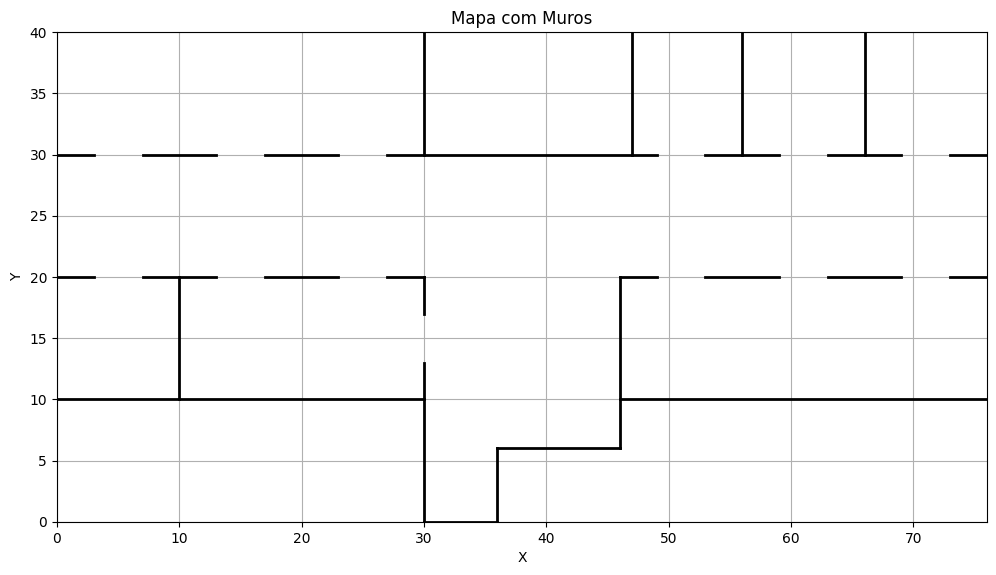

[Mur de longueur 10.0 et de position [[30, 40], [30, 30]],
 Mur de longueur 10.0 et de position [[47, 40], [47, 30]],
 Mur de longueur 10.0 et de position [[56, 40], [56, 30]],
 Mur de longueur 10.0 et de position [[66, 40], [66, 30]],
 Mur de longueur 3.0 et de position [[0, 30], [3, 30]],
 Mur de longueur 6.0 et de position [[7, 30], [13, 30]],
 Mur de longueur 6.0 et de position [[17, 30], [23, 30]],
 Mur de longueur 22.0 et de position [[27, 30], [49, 30]],
 Mur de longueur 6.0 et de position [[53, 30], [59, 30]],
 Mur de longueur 6.0 et de position [[63, 30], [69, 30]],
 Mur de longueur 3.0 et de position [[73, 30], [76, 30]],
 Mur de longueur 3.0 et de position [[0, 20], [3, 20]],
 Mur de longueur 6.0 et de position [[7, 20], [13, 20]],
 Mur de longueur 6.0 et de position [[17, 20], [23, 20]],
 Mur de longueur 3.0 et de position [[27, 20], [30, 20]],
 Mur de longueur 3.0 et de position [[46, 20], [49, 20]],
 Mur de longueur 6.0 et de position [[53, 20], [59, 20]],
 Mur de longueu

In [32]:
# import d'une disposition de murs

# FILEPATH: /C:/Mines_2A/Projet_TECHLAB/ProjectPrograms/ProjectPrograms/Astar_1robot.ipynb
# "C:\Mines_2A\Projet_TECHLAB\ProjectPrograms\ProjectPrograms\Programmes_2024\murs_techlab.xlsx"

# Lis le fichier txt
df_murs = pd.read_excel('../data/murs_techlab.xlsx', header=0)


# On créer une liste de murs
liste_murs = []
for i in range(len(df_murs)):
    position = [[df_murs.iloc[i, 0], df_murs.iloc[i, 1]],
                [df_murs.iloc[i, 2], df_murs.iloc[i, 3]]]
    liste_murs.append(Mur(position))

print(liste_murs[2])


def plot_walls(liste_murs):
    for mur in liste_murs:
        # x_inicial, x_final
        x_values = [mur.position[0][0], mur.position[1][0]]
        # y_inicial, y_final
        y_values = [mur.position[0][1], mur.position[1][1]]
        plt.plot(x_values, y_values, color='black',
                 lw=2)  # Desenha a linha do muro


# Configurar o gráfico
plt.figure(figsize=(12, 8))

# Plotar os muros
plot_walls(liste_murs)

# Ajustes para o gráfico
plt.xlim(0, 76)
plt.ylim(0, 40)
plt.gca().set_aspect('equal', adjustable='box')

# Adicionar título e rótulos
plt.title('Mapa com Muros')
plt.xlabel('X')
plt.ylabel('Y')

# Exibir o gráfico
plt.grid(True)
plt.show()
liste_murs

## Import des portes

Dans un fichier xslx qui donne les coordonnées des portes

In [33]:
# import d'une disposition de portes

# FILEPATH: /C:/Mines_2A/Projet_TECHLAB/ProjectPrograms/ProjectPrograms/Astar_1robot.ipynb
# "C:\Mines_2A\Projet_TECHLAB\ProjectPrograms\ProjectPrograms\Programmes_2024\portes_techlab.xlsx"

# Lis le fichier txt
df_portes = pd.read_excel('../data/portes_techlab.xlsx', header=0)

# On créer une liste de portes
liste_portes = []
for i in range(len(df_portes)):
    liste_portes.append(Porte([[df_portes.iloc[i, 0], df_portes.iloc[i, 1]], [
                        df_portes.iloc[i, 2], df_portes.iloc[i, 3]]], df_portes.iloc[i, 4]))

df_portes
liste_portes[8].ouvrir()
liste_portes[7].ouvrir()
liste_portes[5].ouvrir()
liste_portes[0].ouvrir()
liste_portes[4].ouvrir()
liste_portes[10].ouvrir()
liste_portes

[Porte à la position [[3, 20], [7, 20]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[3, 30], [7, 30]] de largeur 4.0 et de statut fermee,
 Porte à la position [[13, 20], [17, 20]] de largeur 4.0 et de statut fermee,
 Porte à la position [[13, 30], [17, 30]] de largeur 4.0 et de statut fermee,
 Porte à la position [[23, 30], [27, 30]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[49, 30], [53, 30]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[59, 30], [63, 30]] de largeur 4.0 et de statut fermee,
 Porte à la position [[69, 30], [73, 30]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[49, 20], [53, 20]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[59, 20], [63, 20]] de largeur 4.0 et de statut fermee,
 Porte à la position [[69, 20], [73, 20]] de largeur 4.0 et de statut ouverte]

## Algoritme A*

Exemple d'execution dans la classe. Toutes les fonctions sont appelées par la methode *afficher*.

# Exemple 

# Affectation des tâches aux robots

On importe des tâches d'un Excel et on les assignent aux robots. Pour cela on utilise des graphes.

On souhaite qu'une tâche soit construite à partir de sous-tâches (intitulé, coordonées_X, coordonnées_Y, prérequis) qui nécessite une certaine fonction d'un robot. On regroupe les sous-tâches par fonctions. 

In [34]:
# on importes des tâches depuis un fichier xslx

df_sous_taches = pd.read_excel(
    "robots_taches.xlsx", header=0, sheet_name="taches")
df_robots = pd.read_excel("../data/robots_taches.xlsx", header=0, sheet_name="robots")

df_robots

,Nom du robot,Depart_x,Depart_y,Taille,Fonction
0,SPOT,10,26,2,Bras
1,UNITREE_GO1_1,38,10,1,Camera
2,UNITREE_GO1_2,40,10,1,Camera
3,UNITREE_GO1_3,42,10,1,Camera
4,R2D2,70,26,1,Thermometre
5,R5D4,72,26,1,Thermometre


In [35]:
# création des robots
liste_robots = []

for i in range(len(df_robots)):
    nom = df_robots.iloc[i, 0]
    position = [df_robots.iloc[i, 1], df_robots.iloc[i, 2]]
    taille = df_robots.iloc[i, 3]
    fonction = df_robots.iloc[i, 4]
    liste_robots.append(robot(position, taille, nom, fonction))

liste_robots

[Robot SPOT,
 Robot UNITREE_GO1_1,
 Robot UNITREE_GO1_2,
 Robot UNITREE_GO1_3,
 Robot R2D2,
 Robot R5D4]

In [36]:
# creation des taches à partir des sous tâches

liste_sous_taches = []
# on crée une liste de prérequis
liste_prerequis = df_sous_taches['Prérequis'].unique().tolist()

# on crée une tache pour chaque ligne du dataframe, elles seront ensuite regroupées par prérequis

for i in range(len(df_sous_taches)):
    nom = f"sous_taches_{i}"
    action = df_sous_taches.iloc[i, 0]
    lieu = [df_sous_taches.iloc[i, 1], df_sous_taches.iloc[i, 2]]
    prerequis = df_sous_taches.iloc[i, 3]
    duree = df_sous_taches.iloc[i, 4]
    liste_sous_taches.append(Tache(nom, lieu, action, prerequis, duree))

liste_sous_taches[0].liste_lieux
print(liste_sous_taches)

[Tache sous_taches_0, Tache sous_taches_1, Tache sous_taches_2, Tache sous_taches_3, Tache sous_taches_4, Tache sous_taches_5, Tache sous_taches_6, Tache sous_taches_7, Tache sous_taches_8, Tache sous_taches_9, Tache sous_taches_10, Tache sous_taches_11, Tache sous_taches_12, Tache sous_taches_13, Tache sous_taches_14, Tache sous_taches_15, Tache sous_taches_16, Tache sous_taches_17, Tache sous_taches_18, Tache sous_taches_19, Tache sous_taches_20]


## Utilisation d'une métaheuristique pour ordonnancer les sous_tâches

On ordonnance ensemble les tâches qui ont les mêmes prérequis

In [37]:
# fonction cout

def cout(ordre):
    '''
    *Fonction cout* : renvoie le cout d'une liste de taches, en utilisant les distances euclidienne entre les lieux
    Paramètres:
    ordre: liste des taches à effectuer (liste de liste de taille 2)
    '''
    cout = 0
    for i in range(len(ordre)-1):
        cout += np.sqrt((ordre[i][0]-ordre[i+1][0]) **
                        2 + (ordre[i][1]-ordre[i+1][1])**2)
    return cout


def recuit_simule(choix, T0, a=0.5, Q=20, P=1, fatigue=1000):
    """
    On applique l'algorithme du recuit simulé à la solution initiale choix.
    Paramètres:
    - T0: température initiale
    - a: facteur de décroissance de la température
    - Q: nombre d'itérations à température constante
    - P: nombre de solutions retournées
    - fatigue: nombre d'itérations maximum
    - doprint: affiche les résultats
    - doplot: affiche les graphes
    - doplot_improve: affiche uniquement les "sauts" d'amélioration
    - doreturngain: retourne le gain relatif de la solution
    """

    # s veut dire sécurité, on ne veut pas avoir de boucle infinie
    out = []
    cout_init = cout(choix)
    choix_init = choix.copy()

    for _ in range(P):
        # pour la solution numéro i, on réinitialise les variables
        arret = 0
        s = 0
        nb_saut = 0
        T = T0
        memory = (choix_init, cout_init)

        # on voudra tracer l'évolution du coût
        trace = [cout_init]
        trace2 = [cout_init]

        while arret < Q and s < fatigue:
            cout0 = cout(choix)
            choix0 = choix
            trace.append(cout0)

            # obtention d'un voisinge
            # choix = marche_sto(choix,fatigue=1000,limit_jump=30,doprint=False,doplot=False)
            # idée : voisinage améliorant mais trop couteux
            i, j = np.random.randint(
                0, len(choix0)), np.random.randint(0, len(choix0))
            choix0[i], choix0[j] = choix0[j], choix0[i]

            cout1 = cout(choix)

            if cout1 < cout0:
                choix0 = choix
                cout0 = cout1
                # arret = 0
            else:
                p = np.random.rand()
                if p < np.exp(-(cout1-cout0)/T):
                    choix0 = choix
                    cout0 = cout1
                    arret += 1
                    nb_saut += 1
                # si la solution est pire, on la garde avec la probabilité de Boltzmann
                # on ne veut pas rester bloqué dans un minimum local,
                # en revanche si on est coincé trop longtemps, on arrête
            T = a*T

            if cout0 < memory[1]:
                memory = (choix0, cout0)
            trace2.append(memory[1])
            # on garde en mémoire la meilleure solution rencontrée
            s += 1

        out.append(memory)

    return out


# on créer des taches à partir des listes de lieux ordonnées, chaque tache est associée à un prérequis
def creer_taches(liste_prerequis, liste_sous_taches, N):
    '''
    Fonction qui crée des taches à partir des listes de lieux ordonnées, chaque tache est associée à un prérequis
    Paramètres:
    liste_prerequis: liste des prérequis
    liste_sous_taches: liste des sous taches
    N: nombre de sous taches par tache
    '''

    # on crée un dictionsnaire de taches, regroupées par prérequis
    dict_sous_taches = {}
    for prerequis in liste_prerequis:
        dict_sous_taches[prerequis] = [
            tache.liste_lieux for tache in liste_sous_taches if tache.prerequis == prerequis]

    # on ordonance le dictionnaire avec le recuit simulé
    dict_sous_taches_ord = {}
    for prerequis in liste_prerequis:
        dict_sous_taches_ord[prerequis] = recuit_simule(
            dict_sous_taches[prerequis], T0=100, a=0.5, Q=20, P=1, fatigue=1000)[0][0]
    liste_taches_finale = []

    # on veut qu'une tâche soit composée d'au plus N sous tâches

    for prerequis in liste_prerequis:
        for i in range(0, len(dict_sous_taches_ord[prerequis]), N):
            nom = df_sous_taches[df_sous_taches['Prérequis']
                                 == prerequis].iloc[0, 0]
            liste_lieux = dict_sous_taches_ord[prerequis][i: i+N]
            liste_action = [f"action_{i}" for i in range(len(liste_lieux))]
            liste_taches_finale.append(
                Tache(nom, liste_lieux, liste_action, prerequis))

    return liste_taches_finale


liste_taches_finale = creer_taches(liste_prerequis, liste_sous_taches, 3)
liste_taches_finale

[Tache Surveiller,
 Tache Surveiller,
 Tache Surveiller,
 Tache Mesure_Température,
 Tache Mesure_Température,
 Tache Interagir_porte,
 Tache Interagir_porte,
 Tache Interagir_porte]

## Affectation des tâches à l'aide d'un graphe biparti

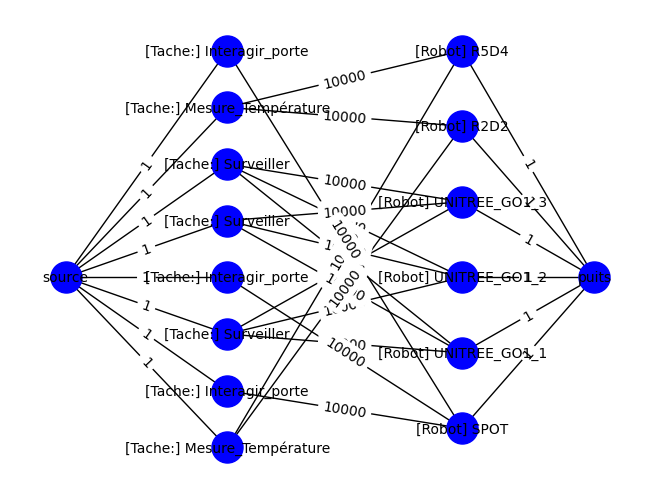

nombre de tâches : 8
nombre de robots : 6



In [38]:
# On définit une fonction qui permet de créer un graphe nx (biparti) à partir d'une liste de tâches et de robots
# (ce seront les noeuds du graphe)
# On suppose que les tâches et les robots sont des listes d'objets de type tache et robot

def create_graph(liste_taches, liste_robots):
    ''' 
    Cette fonction prend en argument une liste de tâches et une liste de robots et renvoie un graphe biparti, avec la source et le puits
    '''
    G = nx.Graph()
    # on ajoute la source et le puits
    G.add_node("source", bipartite=0)
    G.add_node("puits", bipartite=1)

    # on ajoute les tâches et les robots
    # on ajoute les tâches comme noeuds de type 0
    G.add_nodes_from(liste_taches, bipartite=0)
    # on ajoute les robots comme noeuds de type 1
    G.add_nodes_from(liste_robots, bipartite=1)

    # on ajoute les arcs entre les tâches et les robots, si le robot peut effectuer la tâche
    # on donne une capacité de 1 à chaque arc
    for t in liste_taches:
        for r in liste_robots:
            if r.meet_prerequis(tache=t):
                G.add_edge(t, r, weight=10_000)

    # on ajoute les arcs entre la source et les tâches, ainsi que les tâches et le puits
    for t in liste_taches:
        G.add_edge("source", t, weight=1)

    # on ajoute les arcs entre les robots et le puits
    for r in liste_robots:
        G.add_edge(r, "puits", weight=1)
    return G


liste_taches = liste_taches_finale

G = create_graph(liste_taches, liste_robots)

# on affiche le graphe

# on obtient les noeuds de type 0
nodes0 = {n for n, d in G.nodes(data=True) if d['bipartite'] == 0}
# on obtient les noeuds de type 1
nodes1 = {n for n, d in G.nodes(data=True) if d['bipartite'] == 1}


# Modifie la position de la source et du puits
pos = nx.bipartite_layout(G, nodes0)
pos["source"] = (-2, 0)  # Place the source node to the left of the nodes0
pos["puits"] = (2, 0)  # Place the puits node to the right of the nodes1


# Dessine le graphe, en affichant les poids des arcs
nx.draw(G, pos, with_labels=True, node_color="blue",
        node_size=500, font_size=10)


# Créé un dictionnaire des poids des arcs
edge_labels = nx.get_edge_attributes(G, 'weight')

# Dessine les poids des arcs
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

# Plot le graphe
plt.show()

print(f"nombre de tâches : {len(liste_taches)}")
print(f"nombre de robots : {len(liste_robots)}")
print("")

### Obtention de l'affectaton avec Ford-Fulkerson

In [39]:
# on applique l'algorithme de Ford Fulkerson pour trouver le flot maximal, et on en deduis les tâches affectées à chaque robot

def affectation(G):
    """ 
    Comme vu en cours, cette fonction prend en argument un graphe biparti et renvoie une affectation de tâches aux robots
    Par convention, on considère que la source est le noeud 0 et le puits le noeud 1

    Paramètres
    ----------
    G : un graphe biparti nx
    """
    # on récupère le flot maximal, ainsi que le flot
    flow_value, flow_dict = nx.maximum_flow(
        G, "source", "puits", capacity="weight")

    # on retire la source et le puits du dict flow_dict
    flow_dict.pop("source")
    flow_dict.pop("puits")

    # on récupère les tâches et les robots, on retire la source et le puits des listes
    taches = [n for n, d in G.nodes(data=True) if d['bipartite'] == 0]
    taches.remove("source")
    robots = [n for n, d in G.nodes(data=True) if d['bipartite'] == 1]
    robots.remove("puits")

    # on crée un dictionnaire qui associe à chaque tâche le robot qui lui est affecté
    affectation = {}
    for tache in taches:
        for robot in robots:
            if robot.meet_prerequis(tache) and flow_dict[tache][robot] == 1:
                affectation[tache] = robot

                print(f"Position actuelle du robot : {robot.position}")

    return affectation, flow_value


# test de la fonction affectation
affectation(G)

for robot in liste_robots:
    print(f"Position finale du Robot {robot}: {robot.position}")
# une fois l'affectation obtenue, on peut attribuer les tâches à chaque robot


def attribuer_taches(affectation):
    """ 

    Cette méthode prend en argument un dictionnaire affectation qui associe à chaque tâche le robot qui lui est affecté
    et une liste de robots modifie l'attribut tache de chaque robot
    """
    for robot in liste_robots:
        robot.clear_taches()

    for tache, robot in affectation.items():
        robot.taches.append(tache)
        robot.tache = tache


attribuer_taches(affectation(G)[0])

Position actuelle du robot : [40, 10]
Position actuelle du robot : [42, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [72, 26]
Position actuelle du robot : [70, 26]
Position actuelle du robot : [10, 26]
Position actuelle du robot : [10, 26]
Position finale du Robot [Robot] SPOT: [10, 26]
Position finale du Robot [Robot] UNITREE_GO1_1: [38, 10]
Position finale du Robot [Robot] UNITREE_GO1_2: [40, 10]
Position finale du Robot [Robot] UNITREE_GO1_3: [42, 10]
Position finale du Robot [Robot] R2D2: [70, 26]
Position finale du Robot [Robot] R5D4: [72, 26]
Position actuelle du robot : [40, 10]
Position actuelle du robot : [42, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [72, 26]
Position actuelle du robot : [70, 26]
Position actuelle du robot : [10, 26]
Position actuelle du robot : [10, 26]


### Affichage de l'affectation

In [40]:
def afficher_affectation1(affectation):
    """ 
    Cette fonction prend en argument un dictionnaire affectation qui associe à chaque tâche le robot qui lui est affecté
    et renvoie un dataframe pandas qui représente l'affectation
    """
    d = {"Tâches": [], "Robots": []}
    for tache, robot in affectation.items():
        d["Tâches"].append(tache.nom)
        d["Robots"].append(robot.nom)
    return pd.DataFrame(d)


afficher_affectation1(affectation(G)[0])

Position actuelle du robot : [40, 10]
Position actuelle du robot : [42, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [38, 10]
Position actuelle du robot : [72, 26]
Position actuelle du robot : [70, 26]
Position actuelle du robot : [10, 26]
Position actuelle du robot : [10, 26]


,Tâches,Robots
0,Surveiller,UNITREE_GO1_3
1,Surveiller,UNITREE_GO1_1
2,Surveiller,UNITREE_GO1_1
3,Mesure_Température,R5D4
4,Mesure_Température,R2D2
5,Interagir_porte,SPOT
6,Interagir_porte,SPOT


# Exemple 2

[10, 26]
[38, 10]
Position de r5d4: [72, 26]


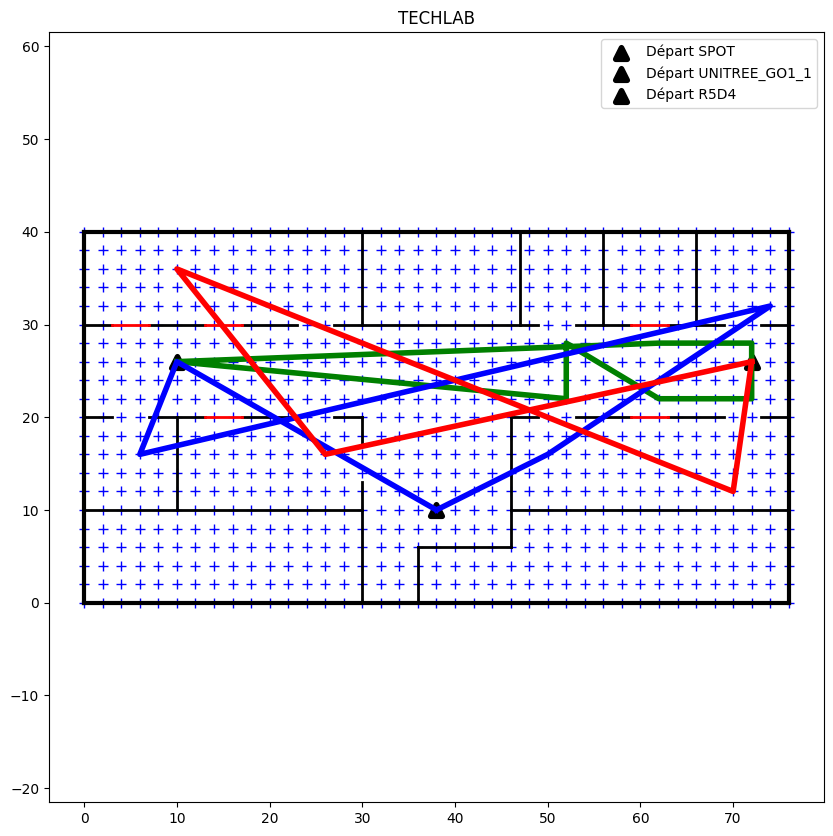

In [41]:
largeur, longueur = 40, 76
room1 = Piece(longueur, largeur, liste_murs, liste_portes)

Unitree_go1 = liste_robots[1]
r5d4 = liste_robots[-1]
SPOT = liste_robots[0]

print(SPOT.position)
print(Unitree_go1.position)

print(f"Position de r5d4: {r5d4.position}")
#r5d4.sumup_robot()
room1.associer_robot(SPOT)
room1.associer_robot(Unitree_go1)
room1.associer_robot(r5d4)

liste_portes[0].ouvrir()
#liste_portes[0].fermer()
liste_portes[4].ouvrir()
liste_portes[10].ouvrir()

room1.afficher(plot_grille=True, grid_size=2,plot_accessible=False, plot_path=True)

# Exemple 3

L'idée est d'avoir un robot qui connait à l'avance son chemin, et qui le parcours petit à petit, en évitant les obstacles à chaque itération.

In [17]:
def conflit(liste_robots):
    """ 
    Fonction qui renvoie True s'il y a un conflit entre les robots, 
    c'est à dire si ils sont sur le même lieu à la même étape
    """
    lieux = []
    for robot in liste_robots:
        if robot.taches:
            lieux.append(robot.taches[0].get_lieu(robot.current_tache))
    return len(lieux) != len(set(lieux))


def assigner_position(room, k=1):
    """
    Methode qui assigne aux robots le chemin qu'ils vont parcourir dans la pièce dynamique 
    En particulier les velurs sont misent à l'échele de la grille
    paramètres:
    room: objet de la classe Piece
    k: facteur d'agrandissement de la grille

    """
    for robot in room.liste_robot:
        position = []
        lieu_depart = robot.position
        lieu_depart = [lieu_depart[0], lieu_depart[1]]

        print(f"[{robot.nom}] lieu départ : {lieu_depart}")

        pathes, _ = room.plus_court_chemin_tsp(
            lieu_depart, grid_size=2, robot=robot, k=1)

        for l in pathes:
            for coord in l:
                x, y = coord
                coord = (x*k, y*k)
                position.append(coord)
        robot.position = position

Position de r5d4: [72, 26]
Position de Unitree_go1: [38, 10]
Position de SPOT: [10, 26]
[UNITREE_GO1_1] lieu départ : [38, 10]
[R5D4] lieu départ : [72, 26]
[SPOT] lieu départ : [10, 26]


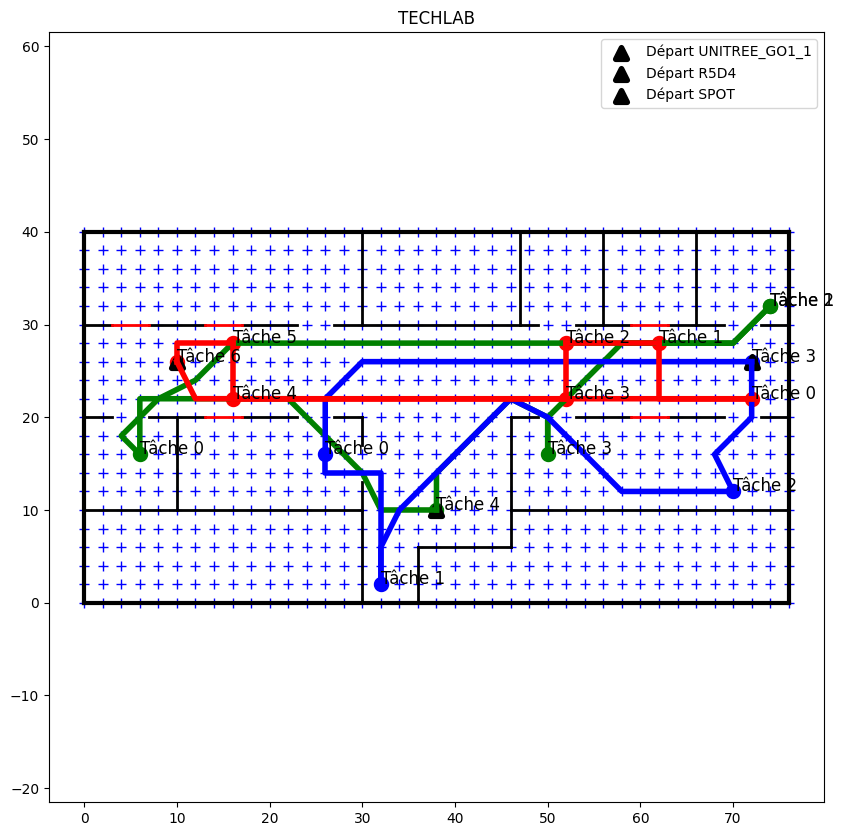

In [18]:
# on créé la pièce
largeur, longueur = 40, 76
room3 = Piece(longueur, largeur, liste_murs, liste_portes)

# on créé les robots
Unitree_go1 = liste_robots[1]
SPOT = liste_robots[0]
r5d4 = liste_robots[-1]

# Debug: verificar posições
print(f"Position de r5d4: {r5d4.position}")
print(f"Position de Unitree_go1: {Unitree_go1.position}")
print(f"Position de SPOT: {SPOT.position}")

# on associe les robots à la pièce
room3.associer_robot(Unitree_go1)
room3.associer_robot(r5d4)
room3.associer_robot(SPOT)
# on assigne leur chemin aux robots
assigner_position(room3)

room3.afficher(plot_grille=True, grid_size=2,
               plot_accessible=False, plot_path=True)

# Représentation dynamique

On utilise la bibliothèque TKinter

In [19]:
from tkinter import *

In [20]:
import tkinter as tk


class GridWindow:
    def __init__(self, master, room, grid_spacing, k=0.5):
        """ 
        Cette classe trace la pièce avec Tkinter, en affichant les murs et les portes
        Paramètres:
        master: objet Tkinter
        rect_width: largeur de la pièce
        rect_height: hauteur de la pièce
        grid_spacing: taille de la grille
        lines: liste des murs
        k: facteur d'agrandissement (ca marche avec 0.5)
        """

        self.master = master
        self.master.title("Pièce")

        self.rect_width = room.longueur
        self.rect_height = room.largeur
        self.grid_spacing = grid_spacing
        self.liste_murs = [m.position for m in room.liste_murs]
        self.liste_portes = [p.position for p in room.liste_portes]
        self.liste_robots = room.liste_robot
        self.k = k
        self.circle_objects = []  # list to store circle objects

        # self.robot_objects = {}  # Círculos para cada robô
        # self.trail_objects = []  # Rastreio (marcas no caminho)

        self.canvas = tk.Canvas(
            master, width=self.rect_width + 25, height=self.rect_height + 25, bg="white")
        self.canvas.pack()

        # Draw rectangle
        self.rectangle = self.canvas.create_rectangle(
            0, 0, self.rect_width, self.rect_height, outline="black", width=3)

        # Draw grid inside the rectangle
        for i in range(self.rect_width // grid_spacing):
            self.canvas.create_line(
                i * grid_spacing, 0, i * grid_spacing, self.rect_height, fill="blue")  # Vertical lines
        for j in range(self.rect_height // grid_spacing):
            self.canvas.create_line(0, j * grid_spacing, self.rect_width,
                                    j * grid_spacing, fill="blue", width=1)  # Horizontal lines

        # On ajoute les coordonnées
        font_size = 7
        self.canvas.create_text(0, self.rect_height + 10,
                                text="0", anchor="nw", font=("Arial", font_size))
        for i in range(1, self.rect_width // grid_spacing):
            i_corr = i * grid_spacing
            self.canvas.create_text(
                i_corr, self.rect_height+10, text=str(i_corr), anchor="nw", font=("Arial", font_size))
        for j in range(1, self.rect_height // grid_spacing):
            j_corr = self.rect_height - j * grid_spacing
            self.canvas.create_text(self.rect_width + 10, j_corr, text=str(j_corr), anchor="nw",
                                    font=("Arial", font_size))

        # Draw walls
        for walls in self.liste_murs:
            self.draw_line(walls)

        # Draw doors
        for door in self.liste_portes:
            self.draw_line(door, color="red", largeur=3)

        # Draw robot
        for robot in self.liste_robots:
            self.draw_robot(robot)

        # Exit button
        self.exit_button = tk.Button(
            master, text="Exit", command=self.exit_window)
        self.exit_button.pack()

        # Move button
        self.move_button = tk.Button(
            master, text="Move", command=self.move_robot)
        self.move_button.pack()

        # Avance rapide
        self.fast_forward_button = tk.Button(
            master, text="Fast forward", command=self.fast_forward)
        self.fast_forward_button.pack()

    def draw_line(self, line, color="black", largeur=3):

        x1, y1 = line[0]
        x2, y2 = line[1]
        x1 *= self.k
        y1 *= self.k
        x2 *= self.k
        y2 *= self.k

        h = self.rect_height
        # Corrige apenas o eixo Y (invertendo em relação à altura da peça)
        self.canvas.create_line(x1 * self.grid_spacing, h - y1 * self.grid_spacing,
                                x2 * self.grid_spacing, h - y2 * self.grid_spacing,
                                fill=color, width=largeur)

    def draw_robot(self, robot, color="blue"):

        x, y = robot.position[robot.current_lieu][0], robot.position[robot.current_lieu][1]
        print(x, y, self.k)
        r = robot.taille
        """x *= self.k
        y *= self.k
        r *= self.k"""

        h = self.rect_height
        circle_obj = self.canvas.create_oval(
            ((x - r)), (h - (y + r)),  # Canto superior esquerdo invertido
            ((x + r)), (h - (y - r)),  # Canto inferior direito invertido
            outline=color, width=10
        )
        # pour le suprimer éventuellement
        self.circle_objects.append(circle_obj)
        print(
            f"robot : {robot.nom}, position : {robot.position[robot.current_lieu]} a été tracé")
        print(f"Posição final do robô: {robot.position[robot.current_lieu]}")
        print(x, y)

        # self.robot_objects[robot.nom] = circle_obj

    def delete_circle(self, index):
        circle_obj = self.circle_objects[index]
        self.canvas.delete(circle_obj)
        del self.circle_objects[index]

    def exit_window(self):
        self.master.destroy()

    def move_robot(self):

        for robot in self.liste_robots:
            # on vérifie d'abord que le robot peut effectuer la tâche (ie. qu'il est sur le bon lieu)
            if robot.taches[robot.current_tache].get_lieu(robot.current_tache) == robot.position[robot.current_lieu]:
                robot.effectuer_tache()
                # on marque le lieu comme visité
                x, y = robot.position[robot.current_lieu][0], robot.position[robot.current_lieu][1]
                x *= self.k
                y *= self.k
                self.canvas.create_oval(
                    (x-5), (y-5), (x+5), (y+5), fill="red", width=10)

            if robot.current_lieu < len(robot.position) - 1:

                robot.current_lieu += 1
                self.delete_circle(0)
                self.draw_robot(robot)

            else:
                self.delete_circle(0)
                self.draw_robot(robot, color='gray')

    def fast_forward(self):
        for _ in range(10):
            self.move_robot()


def piece_dynamique(room):
    root = tk.Tk()
    app = GridWindow(root, room, grid_spacing=20)
    root.mainloop()

    # on fait se déplacer les robots

# Exemple 4

L'idée Tkinter

In [21]:
Unitree_go1.reset_position()
SPOT.reset_position()
r5d4.reset_position()

Avant reset: [(38, 10), (32, 10), (30, 14), (26, 18), (22, 22), (16, 22), (10, 22), (6, 22), (6, 16), (6, 16), (4, 18), (8, 22), (12, 24), (16, 28), (22, 28), (28, 28), (34, 28), (40, 28), (46, 28), (52, 28), (58, 28), (64, 28), (70, 28), (74, 32), (74, 32), (74, 32), (70, 28), (64, 28), (58, 28), (54, 24), (50, 20), (50, 16), (50, 16), (50, 20), (46, 22), (42, 18), (38, 14), (38, 10)]
Après reset: [38, 10]
Avant reset: [(10, 26), (12, 22), (18, 22), (24, 22), (30, 22), (36, 22), (42, 22), (48, 22), (54, 22), (60, 22), (66, 22), (72, 22), (72, 22), (66, 22), (62, 22), (62, 28), (62, 28), (56, 28), (52, 28), (52, 28), (52, 22), (52, 22), (46, 22), (40, 22), (34, 22), (28, 22), (22, 22), (16, 22), (16, 22), (16, 28), (16, 28), (10, 28), (10, 26)]
Après reset: [10, 26]
Avant reset: [(72, 26), (66, 26), (60, 26), (54, 26), (48, 26), (42, 26), (36, 26), (30, 26), (26, 22), (26, 16), (26, 16), (26, 14), (32, 14), (32, 8), (32, 2), (32, 2), (32, 6), (34, 10), (38, 14), (42, 18), (46, 22), (50

In [22]:
murs = [m.position for m in liste_murs]
portes = [p.position for p in liste_portes if p.statut == "ouverte"]

room4 = Piece(76, 40, liste_murs=liste_murs, liste_portes=liste_portes)

# on créé les robots


SPOT.sumup_robot()
Unitree_go1.sumup_robot()
r5d4.sumup_robot()

# on associe les robots à la pièce
room4.associer_robot(SPOT)
room4.associer_robot(r5d4)
room4.associer_robot(Unitree_go1)

# on assigne leur chemin aux robots
assigner_position(room4, k=10)

room4.longueur = 760
room4.largeur = 400

piece_dynamique(room4)


-----------------
Robot [SPOT]
-------
Tâches:
Nom: Interagir_porte
Lieux: [[52, 22], [16, 28], [16, 22]]
Actions: ['action_0', 'action_1', 'action_2']

Nom: Interagir_porte
Lieux: [[52, 28], [72, 22], [62, 28]]
Actions: ['action_0', 'action_1', 'action_2']

Quantite de taches: 6
Fonction: Bras
Position: [10, 26]
Taille: 2
-----------------

-----------------
Robot [UNITREE_GO1_1]
-------
Tâches:
Nom: Surveiller
Lieux: [[6, 16], [74, 32], [74, 32]]
Actions: ['action_0', 'action_1', 'action_2']

Nom: Surveiller
Lieux: [[50, 16]]
Actions: ['action_0']

Quantite de taches: 3
Fonction: Camera
Position: [38, 10]
Taille: 1
-----------------

-----------------
Robot [R5D4]
-------
Tâches:
Nom: Mesure_Température
Lieux: [[70, 12], [32, 2], [26, 16]]
Actions: ['action_0', 'action_1', 'action_2']

Quantite de taches: 3
Fonction: Thermometre
Position: [72, 26]
Taille: 1
-----------------
[SPOT] lieu départ : [10, 26]
[R5D4] lieu départ : [72, 26]
[UNITREE_GO1_1] lieu départ : [38, 10]
100 260 0.

# Exemple 5

L'idée TSP

In [23]:
Unitree_go1.reset_position()
SPOT.reset_position()
r5d4.reset_position()

scale = lambda x: [coord / 10 for coord in x]

Unitree_go1.position = scale(Unitree_go1.position)
SPOT.position = scale(SPOT.position)
r5d4.position = scale(r5d4.position)

Avant reset: [(380, 100), (320, 100), (300, 140), (260, 180), (220, 220), (160, 220), (100, 220), (60, 220), (60, 160), (60, 160), (40, 180), (80, 220), (120, 240), (160, 280), (220, 280), (280, 280), (340, 280), (400, 280), (460, 280), (520, 280), (580, 280), (640, 280), (700, 280), (740, 320), (740, 320), (740, 320), (700, 280), (640, 280), (580, 280), (540, 240), (500, 200), (500, 160), (500, 160), (500, 200), (460, 220), (420, 180), (380, 140), (380, 100)]
Après reset: [380, 100]
Avant reset: [(100, 260), (120, 220), (180, 220), (240, 220), (300, 220), (360, 220), (420, 220), (480, 220), (540, 220), (600, 220), (660, 220), (720, 220), (720, 220), (660, 220), (620, 220), (620, 280), (620, 280), (560, 280), (520, 280), (520, 280), (520, 220), (520, 220), (460, 220), (400, 220), (340, 220), (280, 220), (220, 220), (160, 220), (160, 220), (160, 280), (160, 280), (100, 280), (100, 260)]
Après reset: [100, 260]
Avant reset: [(720, 260), (660, 260), (600, 260), (540, 260), (480, 260), (42


-----------------
Robot [SPOT]
-------
Tâches:
Nom: Interagir_porte
Lieux: [[52, 22], [16, 28], [16, 22]]
Actions: ['action_0', 'action_1', 'action_2']

Nom: Interagir_porte
Lieux: [[52, 28], [72, 22], [62, 28]]
Actions: ['action_0', 'action_1', 'action_2']

Quantite de taches: 6
Fonction: Bras
Position: [56, 24]
Taille: 2
-----------------
[SPOT] lieu départ : [56, 24]


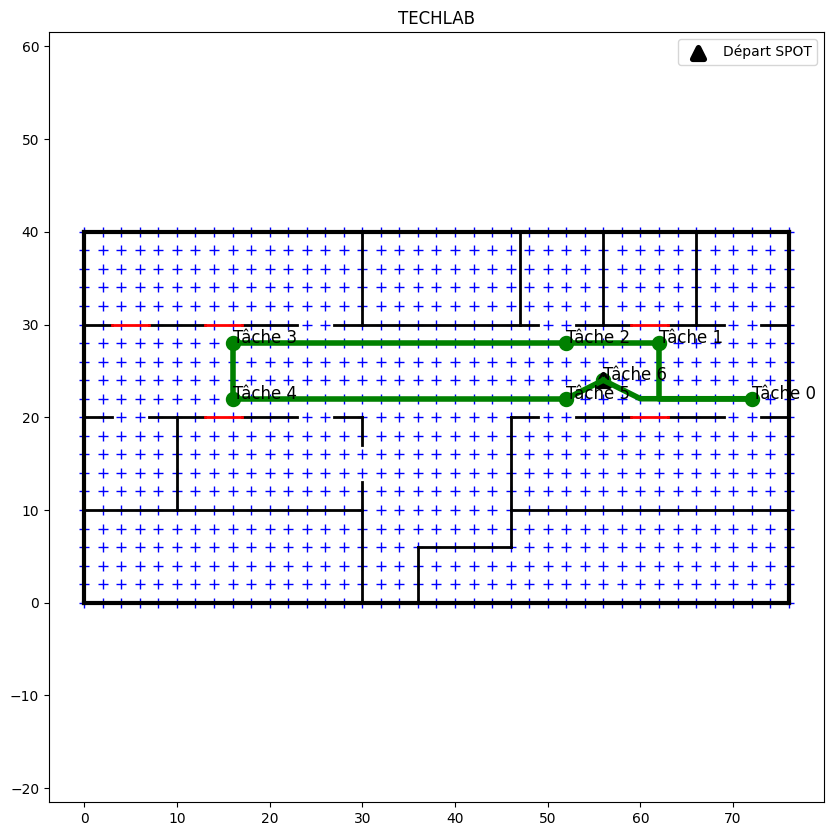

560 240 0.5
robot : SPOT, position : (560, 240) a été tracé
Posição final do robô: (560, 240)
560 240
600 220 0.5
robot : SPOT, position : (600, 220) a été tracé
Posição final do robô: (600, 220)
600 220
660 220 0.5
robot : SPOT, position : (660, 220) a été tracé
Posição final do robô: (660, 220)
660 220
720 220 0.5
robot : SPOT, position : (720, 220) a été tracé
Posição final do robô: (720, 220)
720 220
720 220 0.5
robot : SPOT, position : (720, 220) a été tracé
Posição final do robô: (720, 220)
720 220
660 220 0.5
robot : SPOT, position : (660, 220) a été tracé
Posição final do robô: (660, 220)
660 220
620 220 0.5
robot : SPOT, position : (620, 220) a été tracé
Posição final do robô: (620, 220)
620 220
620 280 0.5
robot : SPOT, position : (620, 280) a été tracé
Posição final do robô: (620, 280)
620 280
620 280 0.5
robot : SPOT, position : (620, 280) a été tracé
Posição final do robô: (620, 280)
620 280
560 280 0.5
robot : SPOT, position : (560, 280) a été tracé
Posição final do robô:

In [32]:
room5 = Piece(76, 40, liste_murs=liste_murs, liste_portes=liste_portes)

# on créé les robots
SPOT1 = liste_robots[0]
#SPOT1.reset_position()
SPOT1.position

SPOT1.sumup_robot()

# on associe les robots à la pièce
room5.associer_robot(SPOT1)

# on assigne leur chemin aux robots
assigner_position(room5, k=10)

room5.afficher(plot_grille=True, grid_size=2,
               plot_accessible=False, plot_path=True)

room5.longueur = 760
room5.largeur = 400

piece_dynamique(room5)

# Exemple 6

Mieux point de départ

In [34]:
def fonction_cout(point_initial, graphe, room, robot, memorization):
    """
    Calcule le coût total du chemin du robot à partir d'un point de départ donné.
    
    Paramètres :
    - point_initial : (x, y) coordonnées du point de départ dans le graphe.
    - graphe : graphe déjà construit pour éviter des recalculs.
    - room : objet représentant l'environnement.
    - robot : objet représentant le robot.
    - memorization : dictionnaire pour éviter de recalculer des coûts déjà trouvés.

    Retourne :
    - Distance totale parcourue si le point est valide.
    - float('inf') si le point est invalide (exemple : à l'intérieur d'une salle fermée).
    """
    
    # Vérifier si le point est accessible dans le graphe
    if point_initial not in graphe:
        return float('inf')  # Pénaliser les points invalides
    
    if point_initial in memorization:
        return memorization[point_initial]
    
    # Calculer le TSP à partir de ce point initial
    try:
        _, _, distance_totale = room.plus_court_chemin_tsp_otimise(point_initial, graphe, grid_size=2, robot=robot)
        memorization[point_initial] = distance_totale  # Mise en cache
        return distance_totale
    except ValueError:  # S'il n'existe pas de chemin valide
        return float('inf')
    

def recuit_simule(room, robot, temperature_initiale=100000, taux_refroidissement=0.99, max_iter=1000):
    """
    Algorithme de Recuit Simulé pour trouver le meilleur point de départ pour le robot.

    Paramètres :
    - room : objet représentant l'environnement.
    - robot : robot qui doit optimiser son point de départ.
    - temperature_initiale : température initiale de l'algorithme.
    - taux_refroidissement : taux de refroidissement de l'algorithme.
    - max_iter : nombre maximal d'itérations.

    Retourne :
    - Meilleur point de départ trouvé.
    """
    
    # Générer des points candidats valides
    graphe = nx.Graph(room.get_graphe(grid_size=2, robot=robot))  # Calcul du graphe une seule fois
    points_valides = list(graphe.nodes)
    print(points_valides)
    
    if not points_valides:
        raise ValueError("Aucun point valide trouvé dans le graphe.")

    # Initialisation
    memorization = {}  # Cache pour éviter les recalculs
    meilleur_point = random.choice(points_valides)
    meilleur_cout = fonction_cout(meilleur_point, graphe, room, robot, memorization)

    memorization[meilleur_point] = meilleur_cout

    meilleure_solution = meilleur_point
    meilleure_distance = meilleur_cout

    temperature = temperature_initiale

    for _ in range(max_iter):
        
        voisin = random.choice(points_valides)

        if voisin in memorization:
            nouveau_cout = memorization[voisin]
        else:
            nouveau_cout = fonction_cout(voisin, graphe, room, robot, memorization)
        
        delta = nouveau_cout - meilleur_cout
        if delta < 0 or random.random() < math.exp(-delta / temperature):
            meilleur_point, meilleur_cout = voisin, nouveau_cout
            
        # Si le nouveau coût est meilleur, toujours accepter
        if nouveau_cout < meilleure_distance:
            meilleure_solution, meilleure_distance = voisin, nouveau_cout

        # Refroidissement de la température
        temperature *= taux_refroidissement
        if temperature < 1e-3:
            break

    return meilleure_solution


In [26]:
import itertools

def recherche_exhaustive(room, robot):
    """
    Algorithme de recherche exhaustive pour trouver le meilleur point de départ.

    Paramètres :
    - room : objet représentant l'environnement.
    - robot : robot qui doit optimiser son point de départ.

    Retourne :
    - Meilleur point de départ trouvé et son coût minimal.
    """
    
    # Récupérer le graphe et tous les points valides
    graphe = nx.Graph(room.get_graphe(grid_size=2, robot=robot))  # Calcul du graphe une seule fois
    points_valides = list(graphe.nodes)
    
    if not points_valides:
        raise ValueError("Aucun point valide trouvé dans le graphe.")

    # Initialisation des meilleures valeurs
    memorization = {}  # Cache pour éviter les recalculs
    meilleure_solution = None
    meilleure_distance = float('inf')

    # Tester chaque point dans la liste des points valides
    for i, point in enumerate(points_valides):
        
        if point in memorization:
            cout_actuel = memorization[point]
        else:
            cout_actuel = fonction_cout(point, graphe, room, robot, memorization)
            memorization[point] = cout_actuel  # Mise en cache

        # Vérifier si c'est le meilleur résultat trouvé
        if cout_actuel < meilleure_distance:
            meilleure_solution = point
            meilleure_distance = cout_actuel

    return meilleure_solution, meilleure_distance


In [27]:
SPOT.reset_position()
SPOT.position = scale(SPOT.position)
SPOT.position

Avant reset: [(100.0, 260.0), (120, 220), (180, 220), (240, 220), (300, 220), (360, 220), (420, 220), (480, 220), (540, 220), (600, 220), (660, 220), (720, 220), (720, 220), (660, 220), (620, 220), (620, 280), (620, 280), (560, 280), (520, 280), (520, 280), (520, 220), (520, 220), (460, 220), (400, 220), (340, 220), (280, 220), (220, 220), (160, 220), (160, 220), (160, 280), (160, 280), (100, 280), (100, 260)]
Après reset: [100.0, 260.0]


[10.0, 26.0]

In [ ]:
room6 = Piece(76, 40, liste_murs=liste_murs, liste_portes=liste_portes)

# on créé les robots
SPOT = liste_robots[0]
SPOT.position

SPOT.sumup_robot()

# on associe les robots à la pièce
room6.associer_robot(SPOT)
room6.associer_robot(Unitree_go1)
room6.associer_robot(r5d4)


# Encontrar o melhor ponto inicial antes de calcular a TSP
#melhor_ponto_inicial = recuit_simule(room6, SPOT)
melhor_ponto_inicial, melhor_distancia = recherche_exhaustive(room6, SPOT)
print(f"Melhor ponto encontrado: {melhor_ponto_inicial}, Distância: {melhor_distancia}")

# Agora rodamos a TSP a partir desse ponto otimizado
caminho_otimizado, _ = room6.plus_court_chemin_tsp(melhor_ponto_inicial, grid_size=2, robot=SPOT)

print(melhor_ponto_inicial)
print(caminho_otimizado)




-----------------
Robot [SPOT]
-------
Tâches:
Nom: Interagir_porte
Lieux: [[52, 22], [16, 28], [16, 22]]
Actions: ['action_0', 'action_1', 'action_2']

Nom: Interagir_porte
Lieux: [[52, 28], [72, 22], [62, 28]]
Actions: ['action_0', 'action_1', 'action_2']

Quantite de taches: 6
Fonction: Bras
Position: [10.0, 26.0]
Taille: 2
-----------------
Melhor ponto encontrado: (56, 24), Distância: 29
(56, 24)
[[(56, 24), (60, 22), (66, 22), (72, 22)], [(72, 22), (66, 22), (62, 22), (62, 28)], [(62, 28), (56, 28), (52, 28)], [(52, 28), (46, 28), (40, 28), (34, 28), (28, 28), (22, 28), (16, 28)], [(16, 28), (16, 22)], [(16, 22), (22, 22), (28, 22), (34, 22), (40, 22), (46, 22), (52, 22)], [(52, 22), (56, 24)]]


In [29]:
print(SPOT.position)
print(type(SPOT))
print(robot.__dict__)
print(SPOT.deplacer)
SPOT.deplacer(list(melhor_ponto_inicial))

print(SPOT.position)

[10.0, 26.0]
<class '__main__.robot'>
{'position': [72.0, 26.0], 'taille': 1, 'type': 'robot', 'nom': 'R5D4', 'taches': [Tache Mesure_Température], 'current_tache': 0, 'current_lieu': 0, 'fonction': 'Thermometre', 'tache': Tache Mesure_Température}
<bound method robot.deplacer of Robot SPOT>
Antes de mudar posição
Depois de mudar posição
[56, 24]


In [30]:
room7 = Piece(76, 40, liste_murs=liste_murs, liste_portes=liste_portes)
room7.associer_robot(SPOT)
print(SPOT.position)
room7.liste_robot
room7.depart

[56, 24]


[[56, 24]]

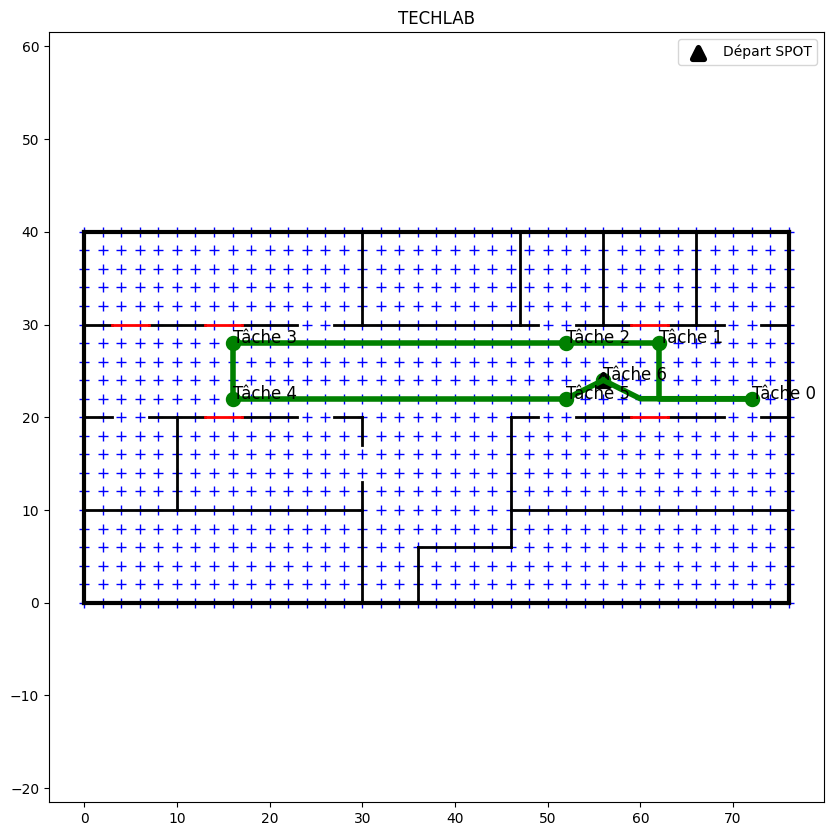

In [31]:
room7.afficher(plot_grille=True, grid_size=2,plot_accessible=False, plot_path=True)